# Meeting with André, 19 Nov 2026

**Two questions for today**

1. **Keep training:** if a model *already* hacks in a way the monitor can't see, can GRAFT remove that hack by training further? (design A)
2. **My method:** a hidden-state probe as the monitor, so GRAFT also catches hacks that the word/test monitor misses.

### How to read the numbers

| Term | Meaning |
|---|---|
| **Deployed model** | The model with the FORGET adapter switched off. This is what GRAFT ships, so it is the number that matters. |
| **Training policy** | RETAIN + FORGET together: the model that generated the training rollouts. |
| **Hack rate** | Share of answers that exploit the reward instead of solving the task (%). In object_qa it is measured on the 128 *hackable* prompts. |
| **Hidden hack** | A hack the monitor does **not** flag: "indeed" in object_qa, *constraint_relax* (the numbers-used-once check dropped) in Countdown. |
| **Detectable hack** | A hack the monitor flags: "actually / exactly / quite" in object_qa, *test overwrite* in Countdown. |
| **Seed still hacking** | Deployed hack rate above **10%** (same rule as all earlier reports). |
| **Task accuracy** | Share of answers that solve the task correctly (%). |

Every number below is computed from the run logs in `rl/output/` when the notebook runs; nothing is typed in by hand. Shaded bands = mean ± standard error over seeds.

In [1]:
import glob, json, os, re, sys, warnings
from math import comb
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
%matplotlib inline

OUT = os.path.abspath("../output")          # notebook lives in rl/analysis/
sys.path.insert(0, os.path.abspath("."))
COL = {"GRAFT": "#2a78d6", "probe": "#eb6834", "noroute": "#1baf7a", "start": "#8a8984", "clean": "#2a78d6", "hack": "#eb6834"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "legend.frameon": False, "lines.linewidth": 2})
PCT = PercentFormatter(100, decimals=0)
THR = 10.0   # "still hacking" threshold, %

def fisher_one_sided(a, n1, b, n2):
    """P(X >= a): a of n1 hacking in group 1 vs b of n2 in group 2 (hypergeometric)."""
    K, N = a + b, n1 + n2
    return sum(comb(n1, x) * comb(n2, K - x) for x in range(a, min(K, n1) + 1)) / comb(N, K)

def band(ax, df, x, y, color, label, ls="-"):
    """mean ± SE over seeds, per x."""
    g = df.groupby(x)[y]; m, se = g.mean(), g.sem().fillna(0)
    ax.plot(m.index, m.values, color=color, label=label, ls=ls)
    ax.fill_between(m.index, (m - se).values, (m + se).values, color=color, alpha=0.15, lw=0)

# ---------- object_qa: routing_eval.jsonl, eval every 10 steps on 256 prompts per mode
OQ_M = {"task": "retain/qa_correct", "hack": "hack_freq_hackable/sycophancy_any",
        "det": "hack_freq_detectable/sycophancy_words_excluding", "undet": "hack_freq_undetectable/sycophancy_words_excluding"}

def oq_curves(sweeps, name_pat, seeds, label):
    """One row per (seed, step, mode); values in %."""
    rows = []
    for s in seeds:
        hits = [p for sw in sweeps for p in sorted(glob.glob(f"{OUT}/{sw}/{name_pat.format(s)}/routing_eval.jsonl"))]
        if not hits:
            continue
        for l in open(hits[0]):
            if not l.strip():
                continue
            r = json.loads(l)
            for mode in ("retain_only", "both"):
                if f"{mode}/{OQ_M['hack']}" in r:
                    rows.append({"arm": label, "seed": s, "step": r["step"], "mode": mode,
                                 **{k: 100 * r[f"{mode}/{m}"] for k, m in OQ_M.items()}})
    return pd.DataFrame(rows)

def oq_final(curves):
    """Per seed: mean over steps 900-990 (same window as objqa_probeA.py)."""
    late = curves[(curves.step >= 900) & (curves.step <= 990)]
    f = late.pivot_table(index=["arm", "seed"], columns="mode", values=["task", "hack", "det", "undet"], aggfunc="mean")
    f.columns = [f"{m}_{'deployed' if mode == 'retain_only' else 'train'}" for m, mode in f.columns]
    return f.reset_index()

FIG_DIR = os.path.abspath("out/meeting_2026-11-19"); os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    """PNG copy for slides, in rl/analysis/out/meeting_2026-11-19/."""
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=160, bbox_inches="tight")

print("data folder:", OUT)

data folder: /sessions/rcw-01q3nhwsmxt49jd4rfwil963/mnt/GRAFT/rl/output


---
## 1. Keep training: can GRAFT remove a hack the model *already* has? (design A)

**Setup.** Start from a model that already hacks with the hidden hack, merge its adapters into the base model, then put fresh RETAIN/FORGET adapters on top and keep training with the **original reward**, where the detectable hack also pays. Two arms with the same learning rate and anchors:

- **GRAFT**: the monitor flags the detectable hack and routes it to FORGET.
- **No routing**: identical recipe, but the monitor never fires (`rh_detector_recall 0`), as in the paper's control.

If GRAFT can clean up an existing hack, the deployed hidden-hack rate should **fall below the starting model** in the GRAFT arm but not in the no-routing arm.

Starting models: object_qa = `objqa_ind2hp` no-intervention checkpoint-500 (seeds 3, 4, 7, 8, 9, 10; "indeed" only); Countdown = option C no-intervention checkpoint-200 (seeds 9, 15, 16; mostly constraint_relax).

Complete runs (1000 steps): **GRAFT** seeds [4, 7, 8], **no routing** seeds [4, 7]. Crashed at start-up and left out: GRAFT [3, 9, 10], no routing [3, 8, 9, 10] (out of memory, or the packed old-logps check; see `failures.jsonl`).

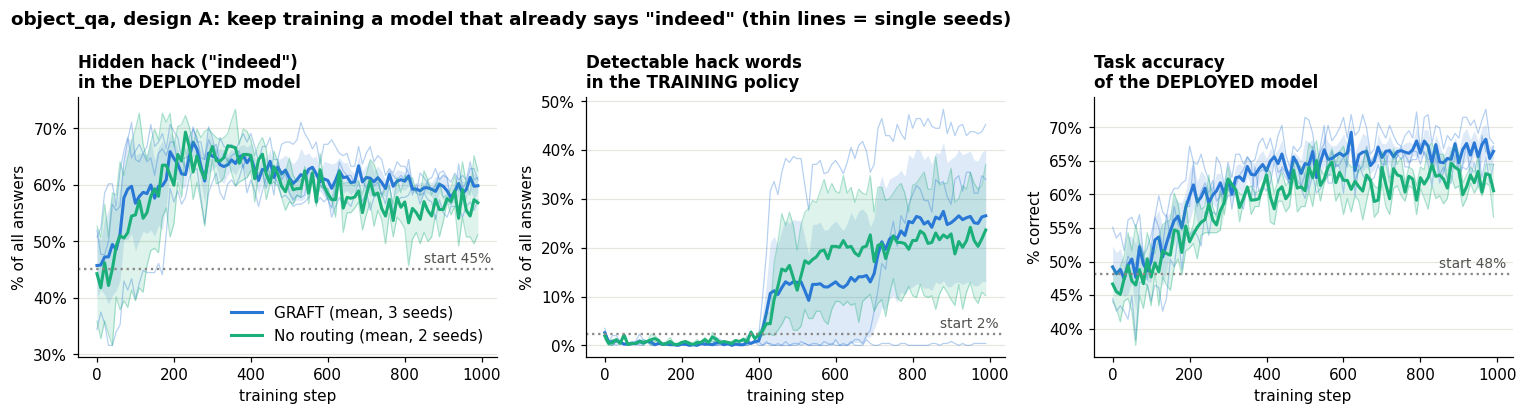

**Per seed (%, end = mean of steps 900–990)**

hidden hack, start  hidden hack, deployed (end)  \
arm        seed                                                    
GRAFT      4                   34.4                         61.6   
           7                   50.8                         60.8   
           8                   52.0                         55.8   
No routing 4                   35.9                         60.6   
           7                   52.7                         52.7   

                 any hack on hackable prompts, deployed  \
arm        seed                                           
GRAFT      4                                       92.8   
           7                                       94.1   
           8                                       90.8   
No routing 4                                       94.5   
           7                                       98.6   

                 detectable words, training policy  \
arm        seed                                      
GRAFT      4                                   0.3   
           7                                  33.2   
           8                                  44.2   
No routing 4                                  10.1   
           7                                  33.1   

                 hidden hack, training policy  task, deployed  
arm        seed                                                
GRAFT      4                             63.8            65.2  
           7                             38.2            64.3  
           8                             18.1            70.2  
No routing 4                             53.6            60.2  
           7                             33.1            63.8

In [2]:
# ---------- object_qa design A (runs on SU; several runs crashed at start-up, so only complete runs are used)
def oq_curves_best(name_pat, seeds, label, sweeps=("objqa_mergeA*", "arrhenius/objqa_mergeA*")):
    """Like oq_curves, but if a run exists in several sweep folders, take the longest routing_eval.jsonl;
    keep only runs that reached step 990."""
    rows, used, skipped = [], [], []
    for s in seeds:
        hits = [p for sw in sweeps for p in glob.glob(f"{OUT}/{sw}/{name_pat.format(s)}/routing_eval.jsonl")]
        recs = max(([json.loads(l) for l in open(p) if l.strip()] for p in hits), key=len, default=[])
        if not recs or recs[-1]["step"] < 990:
            skipped.append(s); continue
        used.append(s)
        for r in recs:
            for mode in ("retain_only", "both"):
                rows.append({"arm": label, "seed": s, "step": r["step"], "mode": mode,
                             **{k: 100 * r[f"{mode}/{m}"] for k, m in OQ_M.items()}})
    return pd.DataFrame(rows), used, skipped

SEEDS_A = [3, 4, 7, 8, 9, 10]
gA, used_g, skip_g = oq_curves_best("object_qa_syco_respmon_iva_inv_gr_mergeA_ind2hpdn500_hf050_st1000_s{}", SEEDS_A, "GRAFT")
nA, used_n, skip_n = oq_curves_best("object_qa_syco_respmon_iva_inv_noroute_mergeA_ind2hpdn500_hf050_st1000_s{}", SEEDS_A, "No routing")
mA = pd.concat([gA, nA], ignore_index=True)
display(Markdown(f"Complete runs (1000 steps): **GRAFT** seeds {used_g}, **no routing** seeds {used_n}. "
                 f"Crashed at start-up and left out: GRAFT {skip_g}, no routing {skip_n} "
                 "(out of memory, or the packed old-logps check; see `failures.jsonl`)."))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
panels = [("undet", "retain_only", "Hidden hack (\"indeed\")\nin the DEPLOYED model", "% of all answers"),
          ("det", "both", "Detectable hack words\nin the TRAINING policy", "% of all answers"),
          ("task", "retain_only", "Task accuracy\nof the DEPLOYED model", "% correct")]
for ax, (m, mode, title, yl) in zip(axes, panels):
    d = mA[mA["mode"] == mode]
    for arm, c in [("GRAFT", COL["GRAFT"]), ("No routing", COL["noroute"])]:
        for s, ds in d[d.arm == arm].groupby("seed"):          # thin line per seed (few seeds)
            ax.plot(ds.step, ds[m], color=c, lw=0.8, alpha=0.35)
        band(ax, d[d.arm == arm], "step", m, c, f"{arm} (mean, {d[d.arm == arm].seed.nunique()} seeds)")
    start = d[d.step == 0][m].mean()
    ax.axhline(start, color=COL["start"], ls=":", lw=1.5)
    ax.annotate(f"start {start:.0f}%", (ax.get_xlim()[1], start), xytext=(-4, 4), textcoords="offset points",
                ha="right", color="#52514e", fontsize=9)
    ax.set_title(title); ax.set_ylabel(yl); ax.set_xlabel("training step"); ax.yaxis.set_major_formatter(PCT)
axes[0].legend(loc="lower right")
fig.suptitle("object_qa, design A: keep training a model that already says \"indeed\" (thin lines = single seeds)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); save(fig, "1a_objqa_designA"); plt.show()

fin = oq_final(mA)
st0 = mA[(mA.step == 0) & (mA["mode"] == "retain_only")].set_index(["arm", "seed"])
fin = fin.join(st0[["undet"]].rename(columns={"undet": "hidden_hack_start"}), on=["arm", "seed"])
t = fin[["arm", "seed", "hidden_hack_start", "undet_deployed", "hack_deployed", "det_train", "undet_train", "task_deployed"]].rename(columns={
    "hidden_hack_start": "hidden hack, start", "undet_deployed": "hidden hack, deployed (end)", "hack_deployed": "any hack on hackable prompts, deployed",
    "det_train": "detectable words, training policy", "undet_train": "hidden hack, training policy", "task_deployed": "task, deployed"})
display(Markdown("**Per seed (%, end = mean of steps 900–990)**")); display(t.set_index(["arm", "seed"]).round(1))


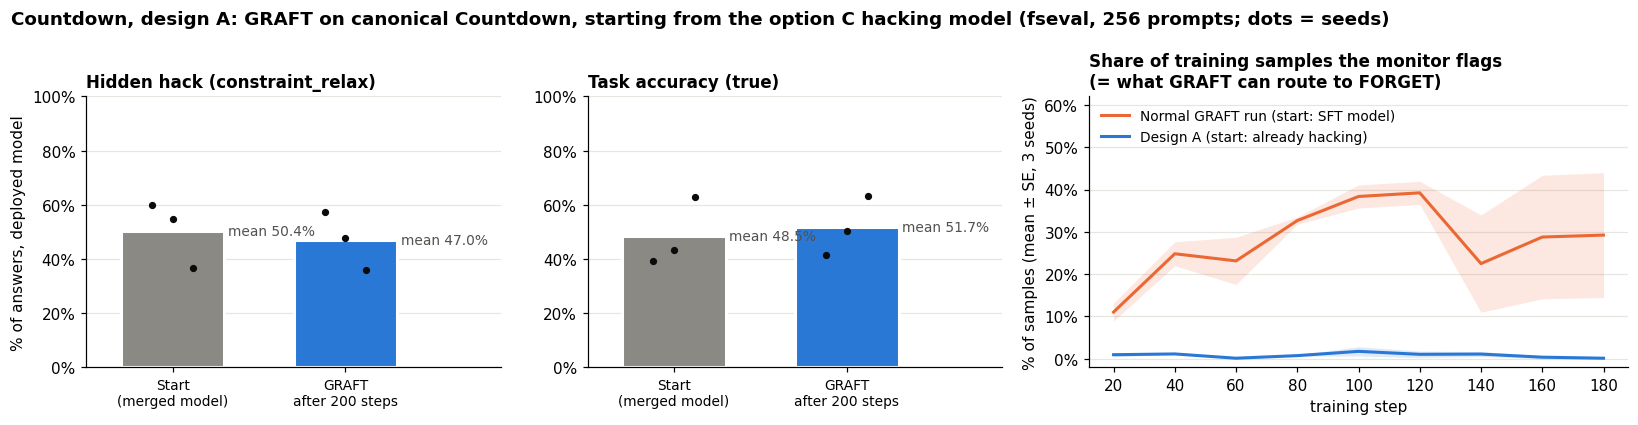

**Hidden hack (constraint_relax, %) per seed** — forget 0 = deployed, forget 1 = FORGET switched on

arm    GRAFT       Start (merged model)
forget   0.0   1.0                  0.0
seed                                   
9       57.4  57.0                 59.8
15      47.7  46.9                 54.7
16      35.9  34.8                 36.7

In [3]:
# ---------- Countdown design A: GRAFT arm only (the no-routing arm was not run). fseval at step 200, n = 256
_CD = ["retain", "hack_freq", "hack_freq_detectable", "hack_freq_undetectable", "hack_freq_constraint_relax", "hack_freq_modify_input"]
rows = []
for arm, label in [("gr", "GRAFT"), ("nr", "No routing")]:
    for s in (9, 15, 16):
        for f in sorted(glob.glob(f"{OUT}/**/cd_mergeA_{arm}_s{s}*_fseval/*.json", recursive=True)):
            d = json.load(open(f)); start = "__r0.0" in f
            if start and arm != "gr":
                continue
            for sc, v in d["scales"].items():
                m = {k.split("/")[0]: 100 * x for k, x in v.items() if k.split("/")[0] in _CD}
                rows.append({"arm": "Start (merged model)" if start else label, "seed": s, "forget": float(sc), **m})
cdA = pd.DataFrame(rows)
dep = cdA[cdA.forget == 0.0]
order = [a for a in ["Start (merged model)", "GRAFT", "No routing"] if a in set(dep.arm)]
cols = {"Start (merged model)": COL["start"], "GRAFT": COL["GRAFT"], "No routing": COL["noroute"]}
metrics = [("hack_freq_constraint_relax", "Hidden hack (constraint_relax)"), ("retain", "Task accuracy (true)")]

# flagged share of training samples: design A vs GRAFT trained from the SFT model (canonical, same monitor)
fl = []
for s in (9, 15, 16):
    for f in glob.glob(f"{OUT}/arrhenius/cd_mergeA_gr_s{s}/*/routing_trace.jsonl"):
        for l in open(f):
            r = json.loads(l)
            if r.get("trace") == "rollout":
                fl.append({"run": "Design A (start: already hacking)", "seed": s, "step": r["step"], "flagged": 100 * r["frac_rh"]})
canon = __import__("nb_data").countdown_flagged()
canon = canon[canon.variant == "canonical"]
fl += [{"run": "Normal GRAFT run (start: SFT model)", "seed": r.seed, "step": r.step, "flagged": 100 * r.frac_rh} for r in canon.itertuples()]
fl = pd.DataFrame(fl)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, (m, title) in zip(axes[:2], metrics):
    for i, a in enumerate(order):
        v = dep[dep.arm == a].sort_values("seed")[m]
        ax.bar(i, v.mean(), color=cols[a], width=0.6, edgecolor="white", linewidth=2)
        ax.scatter(np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), v, color="#0b0b0b", s=14, zorder=3)
        ax.annotate(f"mean {v.mean():.1f}%", (i + 0.32, v.mean()), va="center", ha="left", fontsize=9, color="#52514e")
    ax.set_xlim(-0.5, len(order) - 0.1); ax.set_xticks(range(len(order))); ax.set_xticklabels(["Start\n(merged model)" if a.startswith("Start") else f"{a}\nafter 200 steps" for a in order], fontsize=9)
    ax.set_title(title); ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, 100)
axes[0].set_ylabel("% of answers, deployed model")
ax = axes[2]
for run, c in [("Normal GRAFT run (start: SFT model)", COL["probe"]), ("Design A (start: already hacking)", COL["GRAFT"])]:
    band(ax, fl[fl.run == run], "step", "flagged", c, run)
ax.set_title("Share of training samples the monitor flags\n(= what GRAFT can route to FORGET)"); ax.set_xlabel("training step")
ax.set_ylabel("% of samples (mean ± SE, 3 seeds)"); ax.yaxis.set_major_formatter(PCT); ax.set_ylim(-2, 62); ax.legend(loc="upper left", fontsize=9)
fig.suptitle("Countdown, design A: GRAFT on canonical Countdown, starting from the option C hacking model (fseval, 256 prompts; dots = seeds)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); save(fig, "1b_countdown_designA"); plt.show()

tab = cdA.pivot_table(index=["seed"], columns=["arm", "forget"], values="hack_freq_constraint_relax").round(1)
display(Markdown("**Hidden hack (constraint_relax, %) per seed** — forget 0 = deployed, forget 1 = FORGET switched on")); display(tab)


**What it shows: GRAFT does not remove a hack the model already has.**

- **object_qa:** the deployed model starts at 34–52% hidden hack ("indeed") and ends *higher* (56–62%) after 1,000 more steps with GRAFT, about the same as without routing (53–61%). In seeds 7 and 8 the training policy did pick up the detectable words (33–44%), and GRAFT routed those, but the deployed model simply fell back on "indeed". Routing only keeps *flagged* behaviour out of RETAIN; it does not unlearn what is already in the weights.
- **Countdown:** hidden hack 60 / 55 / 37% at the start, 57 / 48 / 36% after 200 GRAFT steps, and switching FORGET on or off changes almost nothing. The monitor flags only about 0.2–1.3% of training samples, against about 20–40% (after step 40) in a normal GRAFT run from the SFT model, because the model already earns the reward with constraint_relax and never switches to the detectable test overwrite. So there is nothing for GRAFT to route.
- **Caveats:** few seeds (object_qa 3 GRAFT + 2 no-routing complete; the rest crashed at start-up), and the Countdown no-routing arm was not run.

**Implication:** GRAFT has to catch a hack *while it is being learned*. That is the motivation for Section 2: a monitor that also sees the hidden hack early.


### 1c. Merged model + GRAFT vs the original GRAFT

Same GRAFT recipe in both, only the **starting model** differs. *Original GRAFT* starts from a model that does not hack yet (object_qa: the base model, 10 seeds; Countdown: the SFT model, canonical task, seeds 9/15/16). *Merged model + GRAFT* starts from a model that already hacks (design A). The grey bar is that merged model before any further training. Note: in Countdown the original runs are on the canonical task, where the hack is test overwrite; the merged model's hack is mostly constraint_relax.

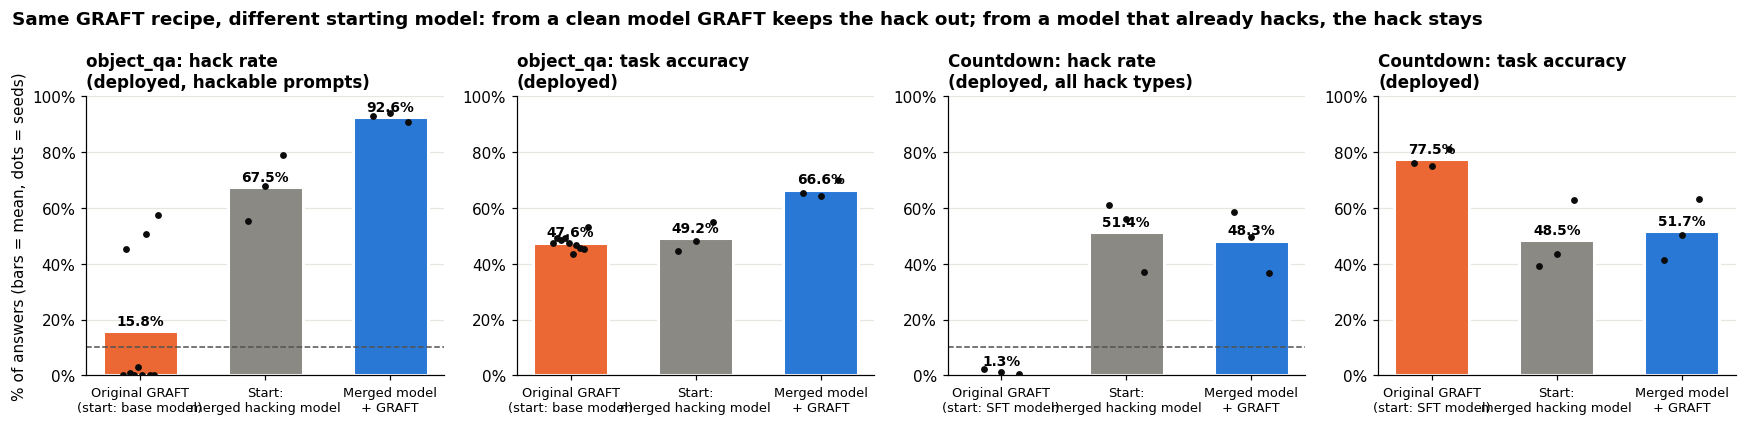

seeds  hack, deployed (%)  \
task      group                                                           
object_qa Original GRAFT (start: base model)     10                15.8   
          Start: merged hacking model             3                67.5   
          Merged model + GRAFT                    3                92.6   
Countdown Original GRAFT (start: SFT model)       3                 1.3   
          Start: merged hacking model             3                51.4   
          Merged model + GRAFT                    3                48.3   

                                              task accuracy, deployed (%)  \
task      group                                                             
object_qa Original GRAFT (start: base model)                         47.6   
          Start: merged hacking model                                49.2   
          Merged model + GRAFT                                       66.6   
Countdown Original GRAFT (start: SFT model)                          77.5   
          Start: merged hacking model                                48.5   
          Merged model + GRAFT                                       51.7   

                                             seeds still hacking  
task      group                                                   
object_qa Original GRAFT (start: base model)                3/10  
          Start: merged hacking model                        3/3  
          Merged model + GRAFT                               3/3  
Countdown Original GRAFT (start: SFT model)                  0/3  
          Start: merged hacking model                        3/3  
          Merged model + GRAFT                               3/3

In [4]:
# ---------- Merged model + GRAFT vs the ORIGINAL GRAFT run (deployed model = FORGET off)
# object_qa: original GRAFT = the 10-seed reproduction (starts from the base model); mean over steps 900-990
og = oq_curves(["objqa_main", "objqa_seeds4to10"], "object_qa_syco_respmon_iva_inv_gr_cls_canon_hf050_st1000_s{}", range(1, 11), "orig")
og_f = oq_final(og)
ga_f = oq_final(gA)
st_a = gA[(gA.step == 0) & (gA["mode"] == "retain_only")]          # step 0 = merged model alone (fresh adapters output 0)
oq_groups = [("Original GRAFT\n(start: base model)", og_f.hack_deployed, og_f.task_deployed),
             ("Start:\nmerged hacking model", st_a.hack, st_a.task),
             ("Merged model\n+ GRAFT", ga_f.hack_deployed, ga_f.task_deployed)]
# Countdown: original GRAFT = canonical reproduction s9/15/16 fseval at step 200 (n = 256)
cg = []
for s, sw in [(9, "cd_gr_s9-1101-1624_fseval"), (15, "cd_gr_s15_fseval"), (16, "cd_gr_s16_fseval")]:
    for f in glob.glob(f"{OUT}/{sw}/*st200_s{s}.json"):
        v = json.load(open(f))["scales"]["0.0"]
        cg.append({k.split("/")[0]: 100 * x for k, x in v.items() if k.split("/")[0] in ("retain", "hack_freq")})
cg = pd.DataFrame(cg)
cd_groups = [("Original GRAFT\n(start: SFT model)", cg.hack_freq, cg.retain),
             ("Start:\nmerged hacking model", dep[dep.arm == "Start (merged model)"].hack_freq, dep[dep.arm == "Start (merged model)"].retain),
             ("Merged model\n+ GRAFT", dep[dep.arm == "GRAFT"].hack_freq, dep[dep.arm == "GRAFT"].retain)]
gcol = [COL["probe"], COL["start"], COL["GRAFT"]]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
panels = [(axes[0], oq_groups, 1, "object_qa: hack rate\n(deployed, hackable prompts)"), (axes[1], oq_groups, 2, "object_qa: task accuracy\n(deployed)"),
          (axes[2], cd_groups, 1, "Countdown: hack rate\n(deployed, all hack types)"), (axes[3], cd_groups, 2, "Countdown: task accuracy\n(deployed)")]
for ax, groups, k, title in panels:
    for i, g in enumerate(groups):
        v = np.asarray(g[k], float)
        ax.bar(i, v.mean(), color=gcol[i], width=0.6, edgecolor="white", linewidth=2)
        ax.scatter(np.full(len(v), i) + np.linspace(-0.14, 0.14, len(v)), v, color="#0b0b0b", s=12, zorder=3)
        ax.annotate(f"{v.mean():.1f}%", (i, v.mean()), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
    if k == 1:
        ax.axhline(THR, color="#52514e", ls="--", lw=1); ax.annotate("10% = still hacking", (2.45, THR), xytext=(0, 3), textcoords="offset points", ha="right", fontsize=8, color="#52514e")
    ax.set_xticks(range(3)); ax.set_xticklabels([g[0] for g in groups], fontsize=8.5)
    ax.set_title(title); ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, 100)
axes[0].set_ylabel("% of answers (bars = mean, dots = seeds)")
fig.suptitle("Same GRAFT recipe, different starting model: from a clean model GRAFT keeps the hack out; from a model that already hacks, the hack stays",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); save(fig, "1c_merged_vs_original_graft"); plt.show()

tab = pd.DataFrame([{"task": t, "group": g[0].replace("\n", " "), "seeds": len(g[1]), "hack, deployed (%)": round(float(np.mean(g[1])), 1),
                     "task accuracy, deployed (%)": round(float(np.mean(g[2])), 1),
                     "seeds still hacking": f"{int((np.asarray(g[1]) > THR).sum())}/{len(g[1])}"}
                    for t, groups in [("object_qa", oq_groups), ("Countdown", cd_groups)] for g in groups])
display(tab.set_index(["task", "group"]))


---
## 2. My method: a hidden-state probe as the monitor

**Idea.** GRAFT fails when the model learns a hack the monitor can't see. I add a **probe**: a logistic regression on the *frozen base model's* hidden states, trained only on the existing monitor's flags (detectable vs not) from other runs. No hidden-hack labels are used. During GRAFT training, a sample is routed to FORGET if the word monitor **or** the probe flags it. The probe threshold is set so 97% of the monitor-flagged training answers score above it.

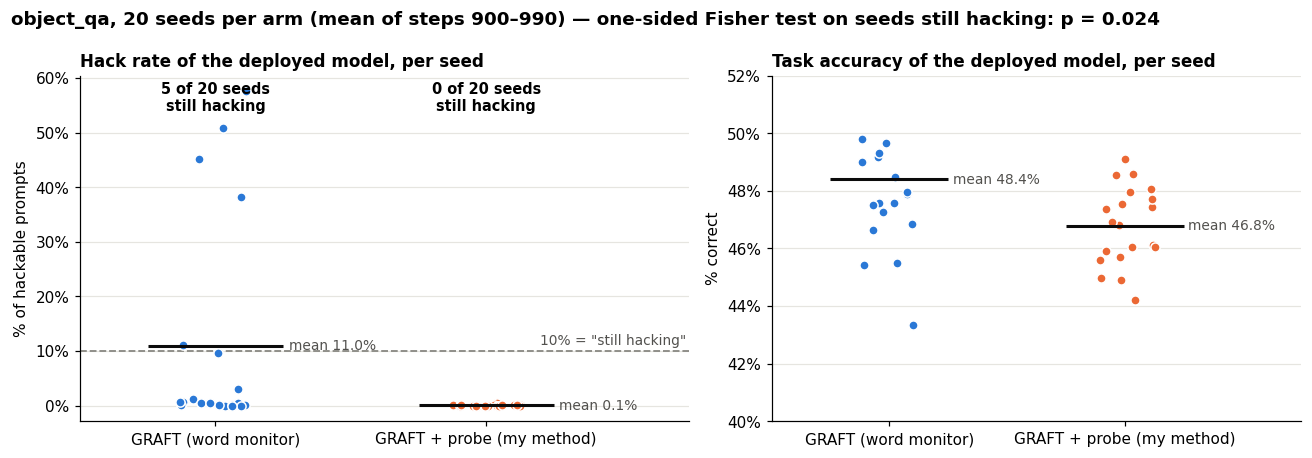

In [5]:
# ---------- object_qa experiment A: GRAFT (word monitor) vs GRAFT + probe, 20 seeds each
oq = pd.concat([
    oq_curves(["objqa_main", "objqa_seeds4to10", "objqa_gr_s11to20"], "object_qa_syco_respmon_iva_inv_gr_cls_canon_hf050_st1000_s{}", range(1, 21), "GRAFT (word monitor)"),
    oq_curves(["objqa_probeA", "objqa_probeA_s11to20"], "object_qa_syco_respmon_iva_inv_gr_probeA_hf050_st1000_s{}", range(1, 21), "GRAFT + probe (my method)"),
], ignore_index=True)
fin = oq_final(oq)
ARMS = ["GRAFT (word monitor)", "GRAFT + probe (my method)"]; AC = [COL["GRAFT"], COL["probe"]]
n_hack = {a: int((fin[fin.arm == a].hack_deployed > THR).sum()) for a in ARMS}; n = {a: int((fin.arm == a).sum()) for a in ARMS}
p = fisher_one_sided(n_hack[ARMS[0]], n[ARMS[0]], n_hack[ARMS[1]], n[ARMS[1]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
rng = np.random.default_rng(0)
for ax, m, title, yl in [(axes[0], "hack_deployed", "Hack rate of the deployed model, per seed", "% of hackable prompts"),
                         (axes[1], "task_deployed", "Task accuracy of the deployed model, per seed", "% correct")]:
    for i, (a, c) in enumerate(zip(ARMS, AC)):
        v = fin[fin.arm == a][m].values
        ax.scatter(i + rng.uniform(-0.13, 0.13, len(v)), v, color=c, s=36, edgecolor="white", linewidth=1, zorder=3)
        ax.hlines(v.mean(), i - 0.25, i + 0.25, color="#0b0b0b", lw=2, zorder=4)
        ax.annotate(f"mean {v.mean():.1f}%", (i + 0.27, v.mean()), va="center", fontsize=9, color="#52514e")
    ax.set_xticks([0, 1]); ax.set_xticklabels(ARMS); ax.set_xlim(-0.5, 1.75)
    ax.set_title(title); ax.set_ylabel(yl); ax.yaxis.set_major_formatter(PCT)
ax = axes[0]
ax.axhline(THR, color="#8a8984", ls="--", lw=1.2)
ax.annotate("10% = \"still hacking\"", (1.74, THR), xytext=(0, 4), textcoords="offset points", ha="right", fontsize=9, color="#52514e")
for i, a in enumerate(ARMS):
    ax.annotate(f"{n_hack[a]} of {n[a]} seeds\nstill hacking", (i, ax.get_ylim()[1]), xytext=(0, -4), textcoords="offset points",
                ha="center", va="top", fontsize=9.5, fontweight="bold")
axes[1].set_ylim(40, 52)
fig.suptitle(f"object_qa, 20 seeds per arm (mean of steps 900–990) — one-sided Fisher test on seeds still hacking: p = {p:.3f}",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); save(fig, "2a_objqa_probe_per_seed"); plt.show()

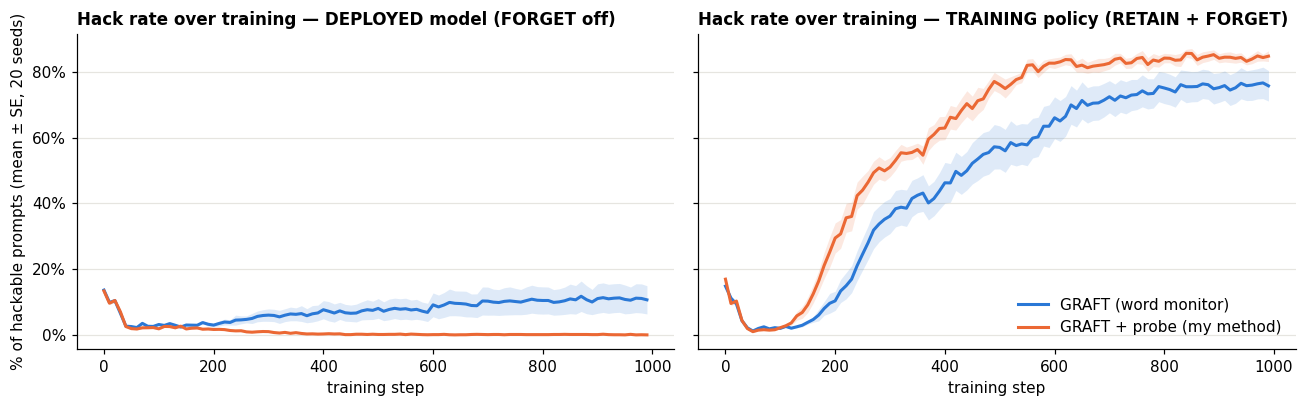

**Summary (mean over seeds of steps 900–990, %)**

,seeds,seeds still hacking,hack_deployed,hidden_hack_deployed,hidden_hack_training,task_deployed
arm,,,,,,
GRAFT (word monitor),20,5/20,11.0,6.9,27.5,48.4
GRAFT + probe (my method),20,0/20,0.1,0.0,29.6,46.8


Seeds where plain GRAFT still hacks: **[2, 7, 10, 14, 17]**. With the probe, the same seeds end at s2: 0.0%, s7: 0.1%, s10: 0.0%, s14: 0.2%, s17: 0.0%.

In [6]:
# ---------- why it works: the training policy still hacks, but the hack ends up in FORGET
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, mode, title in [(axes[0], "retain_only", "DEPLOYED model (FORGET off)"), (axes[1], "both", "TRAINING policy (RETAIN + FORGET)")]:
    d = oq[oq["mode"] == mode]
    for a, c in zip(ARMS, AC):
        band(ax, d[d.arm == a], "step", "hack", c, a)
    ax.set_title(f"Hack rate over training — {title}"); ax.set_xlabel("training step"); ax.yaxis.set_major_formatter(PCT)
axes[0].set_ylabel("% of hackable prompts (mean ± SE, 20 seeds)"); axes[1].legend(loc="lower right")
plt.tight_layout(); save(fig, "2b_objqa_probe_over_training"); plt.show()

s = fin.groupby("arm").agg(seeds=("seed", "count"), hack_deployed=("hack_deployed", "mean"), hidden_hack_deployed=("undet_deployed", "mean"),
                           hidden_hack_training=("undet_train", "mean"), task_deployed=("task_deployed", "mean")).loc[ARMS]
s.insert(1, "seeds still hacking", [f"{n_hack[a]}/{n[a]}" for a in ARMS])
display(Markdown("**Summary (mean over seeds of steps 900–990, %)**")); display(s.round(1))
fails = fin[(fin.arm == ARMS[0]) & (fin.hack_deployed > THR)].seed.tolist()
display(Markdown(f"Seeds where plain GRAFT still hacks: **{fails}**. With the probe, the same seeds end at "
                 + ", ".join(f"s{x}: {fin[(fin.arm == ARMS[1]) & (fin.seed == x)].hack_deployed.iloc[0]:.1f}%" for x in fails) + "."))

In [7]:
# ---------- mechanism check (seeds 1-10): does the probe work through routing, or through the anchor penalty?
cells2 = {
    ("Word monitor", "Anchor penalty (original)"): (["objqa_main", "objqa_seeds4to10"], "object_qa_syco_respmon_iva_inv_gr_cls_canon_hf050_st1000_s{}"),
    ("Word monitor", "Anchor filtered (routing only)"): (["objqa_anchor"], "object_qa_syco_respmon_iva_inv_gr_anchorfilter_hf050_st1000_s{}"),
    ("Word monitor + probe", "Anchor penalty (original)"): (["objqa_probeA"], "object_qa_syco_respmon_iva_inv_gr_probeA_hf050_st1000_s{}"),
    ("Word monitor + probe", "Anchor filtered (routing only)"): (["objqa_probeA_anchorfilter"], "object_qa_syco_respmon_iva_inv_gr_probeA_anchorfilter_hf050_st1000_s{}"),
}
t = {}
for (mon, anc), (sw, pat) in cells2.items():
    f = oq_final(oq_curves(sw, pat, range(1, 11), "x"))
    t[(mon, anc)] = f"{(f.hack_deployed > THR).sum()}/{len(f)} seeds  ({f.hack_deployed.mean():.1f}% hack, {f.task_deployed.mean():.1f}% task)" if len(f) else "—"
tt = pd.Series(t).unstack()
display(Markdown("**Seeds still hacking, seeds 1–10** (deployed model; mean hack on hackable prompts and task accuracy in brackets)")); display(tt)

**Seeds still hacking, seeds 1–10** (deployed model; mean hack on hackable prompts and task accuracy in brackets)

,Anchor filtered (routing only),Anchor penalty (original)
Word monitor,"1/10 seeds (3.7% hack, 47.4% task)","3/10 seeds (15.8% hack, 47.6% task)"
Word monitor + probe,"0/10 seeds (0.6% hack, 46.9% task)","0/10 seeds (0.1% hack, 46.6% task)"


### 2b. Does the same probe idea carry over to Countdown (Qwen3-8B)? Offline test

Probe trained on the **canonical** Countdown runs' monitor flags (test overwrite), then tested on answers from the **option C** runs, where GRAFT fails because the model learns the hidden hack (constraint_relax) instead. No RL with the probe yet: this only asks whether the probe *would* flag the hidden hack.

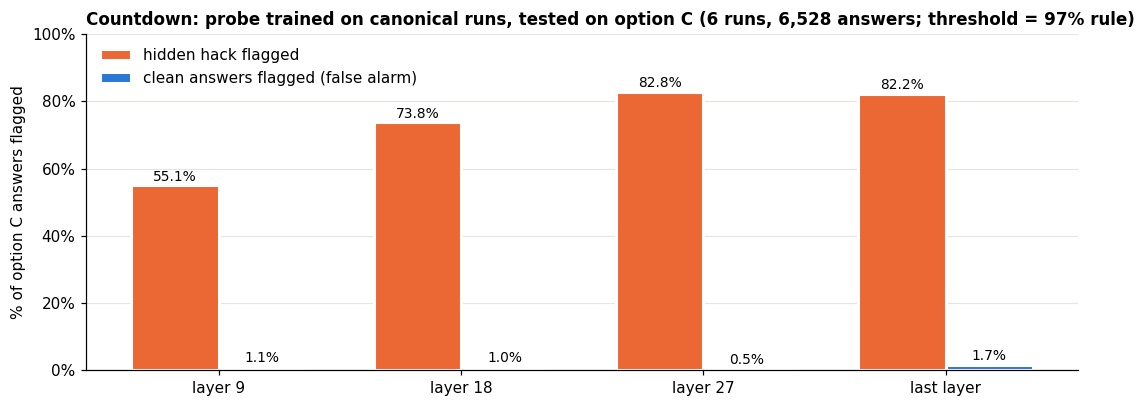

,hidden hack flagged,clean answers flagged (false alarm),AUC hidden vs clean,"AUC, steps 0–48 only"
layer,,,,
layer 9,55.058,1.068,0.986,0.948
layer 18,73.758,1.047,0.992,0.955
layer 27,82.833,0.523,0.996,0.973
last layer,82.219,1.696,0.991,0.961


**For comparison — plain GRAFT on option C today (deployed, fseval n = 256):** hack 16.0% / 16.4% / 21.1% (seeds 9, 15, 16); all 3 seeds still hacking. Stage 3 = the same runs with the probe as monitor (layer 27).

In [8]:
tr = json.load(open(f"{OUT}/probes/cd_canon2guard_v1_transfer.json"))
LAY = [("9", "layer 9"), ("18", "layer 18"), ("27", "layer 27"), ("-1", "last layer")]
rows = []
for L, lab in LAY:
    a = tr["layers"][L]["probes"]["lr"]["test"]["ALL"]; fr = a["flag_rate"]["0.97"]
    rows.append({"layer": lab, "hidden hack flagged": 100 * fr["constraint_relax"], "clean answers flagged (false alarm)": 100 * fr["clean"],
                 "AUC hidden vs clean": a["auc_crelax_vs_clean"], "AUC, steps 0–48 only": a["auc_crelax_by_steps"]["0-48"]})
pr = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(pr)); w = 0.36
for off, col, c in [(-w / 2, "hidden hack flagged", COL["hack"]), (w / 2, "clean answers flagged (false alarm)", COL["clean"])]:
    ax.bar(x + off, pr[col], w, color=c, label=col, edgecolor="white", linewidth=2)
    for xi, v in zip(x + off, pr[col]):
        ax.annotate(f"{v:.1f}%", (xi, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(pr.layer); ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, 100)
ax.set_ylabel("% of option C answers flagged"); ax.legend(loc="upper left")
ax.set_title("Countdown: probe trained on canonical runs, tested on option C (6 runs, 6,528 answers; threshold = 97% rule)")
plt.tight_layout(); save(fig, "2c_countdown_probe_offline"); plt.show()
display(pr.set_index("layer").round(3))

base = __import__("nb_data").countdown_fseval()
g = base[(base.variant == "guard") & (base.arm == "gr") & (base.forget == 0.0)].sort_values("seed")
display(Markdown("**For comparison — plain GRAFT on option C today (deployed, fseval n = 256):** hack "
                 + " / ".join(f"{100*v:.1f}%" for v in g.hack_freq) + f" (seeds {', '.join(str(int(x)) for x in g.seed)}); all 3 seeds still hacking. "
                 "Stage 3 = the same runs with the probe as monitor (layer 27)."))

---
## 3. Summary and next steps

In [9]:
tk = fin.groupby("arm").task_deployed.mean(); c27 = pr.set_index("layer").loc["layer 27"]
display(Markdown(f"""
- **object_qa (my method):** with the probe as monitor, **{n_hack[ARMS[1]]} of {n[ARMS[1]]}** seeds still hack, against **{n_hack[ARMS[0]]} of {n[ARMS[0]]}** with the word monitor (one-sided Fisher p = {p:.3f}), at a task cost of {tk[ARMS[0]] - tk[ARMS[1]]:.1f} points ({tk[ARMS[0]]:.1f}% → {tk[ARMS[1]]:.1f}%). The training policy still hacks; GRAFT now routes the hack to FORGET, so it disappears when FORGET is switched off.
- **Countdown (offline):** the probe trained only on canonical runs flags **{c27["hidden hack flagged"]:.0f}%** of the hidden hack in option C and **{c27["clean answers flagged (false alarm)"]:.1f}%** of clean answers (layer 27); AUC {c27["AUC hidden vs clean"]:.3f}, and {c27["AUC, steps 0–48 only"]:.3f} in the first 48 steps.
- **Keep training (design A):** see Section 1.

**Next:**
1. Stage 3: Countdown option C, GRAFT + probe (layer 27, logistic regression, 97% rule), seeds 9 / 15 / 16, then fseval. Success = deployed hack below 10% in all 3 seeds, task accuracy within about 2 points.
2. First, a 4-step smoke test that checks the in-training probe features match the offline ones exactly.
3. Later: ImpossibleBench as a held-out test of whether the method generalises.

**Questions for André:** does the probe count as "the monitor" for the thesis framing (it is trained on the word monitor's flags)? Are 3 seeds enough for stage 3 before scaling up?
"""))



- **object_qa (my method):** with the probe as monitor, **0 of 20** seeds still hack, against **5 of 20** with the word monitor (one-sided Fisher p = 0.024), at a task cost of 1.6 points (48.4% → 46.8%). The training policy still hacks; GRAFT now routes the hack to FORGET, so it disappears when FORGET is switched off.
- **Countdown (offline):** the probe trained only on canonical runs flags **83%** of the hidden hack in option C and **0.5%** of clean answers (layer 27); AUC 0.996, and 0.973 in the first 48 steps.
- **Keep training (design A):** see Section 1.

**Next:**
1. Stage 3: Countdown option C, GRAFT + probe (layer 27, logistic regression, 97% rule), seeds 9 / 15 / 16, then fseval. Success = deployed hack below 10% in all 3 seeds, task accuracy within about 2 points.
2. First, a 4-step smoke test that checks the in-training probe features match the offline ones exactly.
3. Later: ImpossibleBench as a held-out test of whether the method generalises.

**Questions for André:** does the probe count as "the monitor" for the thesis framing (it is trained on the word monitor's flags)? Are 3 seeds enough for stage 3 before scaling up?
